In [1]:
import sys, time, tempfile
from pathlib import Path
ROOT = Path.cwd().resolve()
while not (ROOT / 'C' / 'evoca.h').exists():
    if ROOT.parent == ROOT:
        raise FileNotFoundError('repo root (C/evoca.h) not found')
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / 'python'))
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from evoca_py import EvoCA, LUT_BYTES
import evoca_explore as ee
WS = 'Lineage-co-evolution'
WSDIR = ROOT / 'Research' / WS
SCANS = WSDIR / 'Scans'
T_NOTEBOOK = time.time()
print('repo root:', ROOT)

repo root: /Users/n/Projects/EvoCA


# Lineage-co-evolution: lab notebook

**Question.** Do the CA-rule genome (the 250-bit LUT) and the eating genome (the egene) co-evolve
*adaptively*, or do they just drift together? And can **lineage-level net metabolic return**
(cumulative intake minus cumulative tax, per lineage) separate adaptation from drift?

This is the chronological lab notebook for the workstream. Newest section at the bottom.
Open questions live in [`ISSUES.md`](ISSUES.md) (single source). Finished digests are in
[`digests/`](digests/) (currently [`coevolution-substrate`](digests/coevolution-substrate.ipynb), a
draft). Raw scans: [`Scans/2026-05-17_pure_evo_egene_on_winners`](Scans/2026-05-17_pure_evo_egene_on_winners/)
(campaign #3), [`Scans/2026-05-19_3c_coevolution_substrate`](Scans/2026-05-19_3c_coevolution_substrate/notes.md)
(#3c), [`Scans/2026-05-19_8_lineage_coevolution`](Scans/2026-05-19_8_lineage_coevolution/scan.py) (#8, on hold,
no results). Planning docs: [`Docs/plan-3c-coevolution-substrate.md`](../../Docs/plan-3c-coevolution-substrate.md),
[`Docs/plan-8-lineage-coevolution.md`](../../Docs/plan-8-lineage-coevolution.md).

**Convention for example runs.** Every example run here is small (N <= 128, <= 3000 steps per phase, seeded) so the
whole notebook executes in a few minutes. Statements marked *observed in this example run* are single-seed
illustrations at small N, **not campaign results**. Recorded campaign results are quoted with their source.

## Open questions snapshot

The cell below renders [`ISSUES.md`](ISSUES.md) as of the last execution of this notebook. **`ISSUES.md` is the
source**; this is only a snapshot and may be stale.

In [2]:
display(Markdown((ROOT / 'Research' / WS / 'ISSUES.md').read_text()))

# Lineage-co-evolution: issues and directions
_Updated 2026-10-15_

The workstream question has two parts: (1) is there adaptive LUT<->egene *coupling* (co-evolution) or just joint drift, and (2) can lineage-level net metabolic return separate adaptation from drift. H1/D3 address part 2; the #8 redesign is the only direct handle on part 1. Example-run evidence cited below comes from `Lineage-co-evolution.ipynb` (single seed, N<=128, not campaign results).

## Decisions needed (N)
- **LIN-D1**: #8 redesign: which fix option, now that D2 exists? (`Docs/plan-8-lineage-coevolution.md` lists A-F; the board lists old #8 as "superseded by D2 + H1", but D2/H1 answer part 2, not the part-1 coupling question.) Options:
  - *Retire #8*, rely on H1 only. Cheapest; leaves "do LUT and egene changes get retained *jointly*?" untested.
  - **Recommended: Option A (Hamming magnitude of LUT bytes vs egene bytes per surviving edge) with `restricted_mu=1` (the existing toggle, i.e. Option F for free), reusing the harness.** Notebook section 3 shows the binary indicator saturating exactly as 1-exp(-250 mu) (0.918 at 0.01, 0.9995 at 0.03) while Hamming keeps mean 250*mu and nonzero spread, and bulk LUT bytes come from one pointer read, so no per-cell loop. Pure Python, no C change. Add the D2 join as phase 2 (below).
  - Option B (add lut_complexity level change) as a secondary read-out; needs a tiny per-cell accessor (dev).
  - Options C, D, E: heavier; keep in reserve if A shows signal but non-monotone coupling (C) or needs temporal persistence (D).
  - Caveats found in the example run: (a) Spearman(LUT Hamming, egene Hamming) was ~0 at every `mu_lut` there, which is the expected null *and* what unpowered silent-bit noise looks like, so run a power check (inject a synthetic coupling) before the campaign; (b) `restricted_mu=1` changes the Poisson rate to `mu_lut * n_active`, so `mu_lut` must be re-chosen; not tested here.
  - Blocks: any #8 campaign. Does not block H1/D3.
- **LIN-D2**: Lineage unit for H1 when `mu_lut` is productive. D2 keys on the full-genome hash, i.e. a *genotype*. Example run: at `mu_lut` >= 0.01 almost every live cell is a unique genotype (fraction sharing a genotype 0.01 at 0.01, 0.0 at 0.03; no hash reaches 10 births at 0.03), so per-hash net return is a per-individual quantity, not a clade property. Options: (a) restrict H1 to `mu_lut` <= ~0.003 where genotypes persist (no dev, but excludes the productive corner used by #3c/#8); (b) clade roll-up in Python along `parent_id` chains from the existing getters (analysis, moderate cost); (c) a C-side clade reducer (dev, only if (b) is too slow). Recommendation: (a) for a first H1 pass plus (b); decide (c) only if needed. Blocks: H1 at the productive corner of the Sec. B sweep.
- **LIN-D3**: Tax basis in the net-return reducer. It counts nominal tax; the dissipation accountant counts tax actually removed. In the example runs the reducer tax was 20-23% above the accountant's (887,729 vs 738,159 evolving; 939,192 vs 763,713 control, N=96, 3000 steps), so per-lineage `net` is biased low, more for short-lived lineages. Options: document and correct in analysis (cheap, loses per-lineage resolution), or add an actual-tax column to the reducer (small C change on merged code, needs N's gate). Recommendation: add the column before H1 conclusions rely on `net`. Blocks: trusting absolute `net` in H1/D3 (relative comparisons within one run are less affected).

## Open questions
- **LIN-Q1**: Is there any adaptive LUT<->egene co-evolution at all? Recorded evidence: #3 3a >> 3b but confounded; #3c says the C-vs-A residual is small (22/30 positive, mean +0.6) and the egene signal weak and plateaued by 7-8k ticks (`Scans/2026-05-19_3c_coevolution_substrate/notes.md`). The direct test (#8) has produced no data (`Scans/2026-05-19_8_lineage_coevolution/` has `scan.py` only). Unanswered.
- **LIN-Q2**: Is the #3c plateau real or a saturation of the cumulative-excess metric? In the 4-seed N=96 replica, C's cumulative `eg_excess_pc` rises and falls with population boom-bust cycles (seed 1: ~250 to ~7000 cells, period ~800 steps). The shadow is not re-baselined at the phase switch (follow-up F1 in `research_board_archival.md`), so absolute excess is biased. Needs F1 or a lineage-based read-out to settle.
- **LIN-Q3**: Raw net return is pinned in a saturated, resource-limited lattice. Example run: total intake equals the food source (~414,000 vs `food_inc*N^2*T` = 414,720) in both arms, and the control's dominant genotype has constant per-capita net -0.020 = `food_inc*N^2/pop - tax`. So what is the right *relative* fitness quantity for H1: net return relative to the same-time population mean, per-lineage growth rate vs shadow (checkpoint Sec. H step 2), or births per capita? D2 output alone does not answer adaptive-vs-drift.
- **LIN-Q4**: Frozen-GoL (3b/B) viability is not reproducible across N, seed, or the RNG stream. Example: config 253 survives at N=128 seed 0 without the neutral shadow and goes extinct with it (seeds 1, 2 extinct either way); the recorded N=256 run survived. Does enabling the shadow perturb the real run's RNG stream (the shadow draws random kills, `C/evoca.c` ~line 2418; not verified)? If so, shadow-on and shadow-off runs are different experiments, which matters for comparing shadow-based campaigns with the shadow-free #8/H1.
- **LIN-Q5**: How often does the `dyn_excess_pc` artifact fire? Recorded: 21 of 30 A runs have slope > 50 (median +249; larger at lower phase-1 `mu_lut`). The N=96 replica showed it in 1 of 4. Understand the N/length dependence before using any dyn-based metric with `mu_lut=0` (rule: only interpret `dyn_excess_pc` where `mu_lut>0`).
- **LIN-Q6**: Provenance gap in campaign #3: `Scans/2026-05-17_pure_evo_egene_on_winners/` has `scan.py` and `results.csv` but no `scan_config.json` and no `notes.md`, so `evoca_from_scan` cannot rebuild its configs. Needs a notes file and a `save_scan_config`-style record (N=256, 8000 steps, halfplane init, GoL LUT; values read from `results.csv`).

## Next directions
- **LIN-N1**: D3 punctuation detector: lineage net-return dip-then-staircase at Negene increments, single unforced run. Kind: needs dev (analysis). Unblocked by the D2 merge. Gaps found: (i) a Negene change creates a *new* hash row, so the detector must link child hash to parent hash; `lineage_parent_hash` gives the parent's hash per newborn but no per-cell full-genome hash accessor exists, and no parent-hash link table is exposed; (ii) `last_step` is only as current as the last `lineage_return_update()`, so trajectories need periodic sampling (longevity resolution = sampling interval); (iii) per LIN-Q3, detect the step in a *relative* quantity. Checkpoint action D3; N's 2026-07-19 note on Sec. D proposes punctuation as a random-slot-addition event (slot activation alone may have negligible effect).
- **LIN-N2**: H1 adaptive-vs-drift program on the Sec. B `food_inc/tax` sweep: lineage net return + A_new + shadow-beating lineage count, with the falsifier (raw activity inverted-U too means the drift-collapse story is wrong). Kind: campaign + analysis. Blockers: G1 (A_new) merged; LIN-D2 (lineage unit), LIN-D3 (tax basis), LIN-Q3 (relative fitness). Checkpoint action H1 (shared with Activity-metrics).
- **LIN-N3**: #8 relaunch per the LIN-D1 outcome: synthetic-coupling power check first, then 2 arms x 8 seeds as in the original spec with `mu_lut` retuned if `restricted_mu=1`. Kind: campaign (pure Python harness exists, flawed observable only). Blocked on LIN-D1.
- **LIN-N4**: Join D2 to the #8 edges: use the child genotype's reducer `births` (reproductive success, not `net`, given LIN-Q3) as the outcome and test the dLUT x dEgene interaction beyond additive effects, with a permutation null. Kind: needs dev (analysis). Blocked on LIN-D1, LIN-D2.
- **LIN-N5**: Re-baseline the shadow at a phase switch (F1) and rerun a #3c-style A/C comparison with lineage read-outs instead of `dyn_excess_pc`. Kind: needs dev (small C change) then campaign. Not started; N to decide priority.
- **LIN-N6**: Finish the `coevolution-substrate` digest (currently a draft in `digests/`) with the section 2 findings, and write `notes.md`/`scan_config.json` for campaign #3 (LIN-Q6). Kind: doc/analysis, no blocker.

## Parked
- Option C/D/E variants of the #8 observable: revisit only if LIN-D1's Option A shows signal that is non-monotone or temporal.
- Evolving-rate genes (`mu-genome`, A2) as a co-evolution lever: tied to the `mu-genome` branch, outside this workstream until it merges.
- Recipes: none exported; the notebook's example runs are scripted (seeded) rather than saved as `.evoca`, because several need mid-run switches (#3c) or post-init `enable_lineage()` that the recipe format does not appear to capture (not checked in detail).


In [3]:
# ---- shared helpers for the example runs ----
def render(sim, mode):
    """Headless lattice frame: colorize() -> ARGB int32 -> RGB uint8 (N, N, 3).
    colormodes: 0 state, 1 env-food, 2 priv-food, 3 births, 4 age."""
    N = sim._N
    px = np.zeros(N * N, np.int32)
    sim.colorize(px, mode)
    a = px.view(np.uint32).reshape(N, N)
    return np.stack([(a >> 16) & 255, (a >> 8) & 255, a & 255], -1).astype(np.uint8)

def mean_negene(sim):
    alive = sim.get_alive() == 1
    if not alive.any():
        return 0.0
    return float(np.unpackbits(sim.get_active()[alive][:, None], axis=1).sum(1).mean())

def sample_basic(sim):
    """One time-series sample: pop, egene excess (cumulative), dyn excess, mean Negene."""
    sim._lib.evoca_eg_activity_update()
    alive = sim.get_alive() == 1
    return dict(pop=int(alive.sum()), eg_excess=float(sim.eg_excess_pc()),
                dyn_excess=float(sim.dyn_excess_pc()), negene=mean_negene(sim))

def slope(t, y):
    return float(np.polyfit(t, y, 1)[0]) if len(t) >= 2 else 0.0

## 1. Campaign #3 (2026-05-17): egene scan on the LUT-only winners, 3a (LUT co-evolving) vs 3b (LUT frozen)

**Question.** Take the top-12 LUT-only (#2) regimes. Does adding egene evolution on top of them produce egene-level
selection (eg-excess) and does it depend on the LUT still evolving? **3a** keeps the winner's `mu_lut`; **3b** sets
`mu_lut=0` (LUT frozen as GoL) and varies only the egene knobs.
Scan: [`Scans/2026-05-17_pure_evo_egene_on_winners/`](Scans/2026-05-17_pure_evo_egene_on_winners/) (288 rows, N=256, 8000 steps; the dir has
`scan.py` and `results.csv` but no `scan_config.json` or `notes.md`, so `evoca_from_scan` cannot build recipes from it; the
example runs below rebuild each configuration from the `results.csv` row via `evoca_explore.build_sim`).

**Recorded finding** (board / archival, row #3): 3a >> 3b (eg-excess ~20 vs ~6), strong apparent co-dependence, **but confounded**:
3b froze *GoL*, not an evolved LUT, and 46% of 3b runs went extinct.

In [4]:
d3 = pd.read_csv(SCANS / '2026-05-17_pure_evo_egene_on_winners' / 'results.csv')
summ = d3.groupby('mode').agg(n=('mode', 'size'), extinct_frac=('extinct', 'mean'),
                              eg_excess_pc_slope_mean=('eg_excess_pc_slope', 'mean'),
                              alive_density_mean=('alive_density_mean', 'mean')).round(3)
print('Recorded campaign #3 results.csv, by mode (N=256, 8000 steps):')
display(summ)

Recorded campaign #3 results.csv, by mode (N=256, 8000 steps):


,n,extinct_frac,eg_excess_pc_slope_mean,alive_density_mean
mode,,,,
3a,144,0.118,17.479,0.194
3b,144,0.458,1.738,0.179


**Example runs.** Two matched 3a/3b pairs from `results.csv` (same base regime and egene knobs; 3b has `mu_lut=0`):
config 252/253 (base regime 10, where both arms survive in the campaign) and 236/237 (base regime 9, where 3b went extinct).
Run at **N=128, 3000 steps, seed 0** with lineage tracking and the neutral shadow on.

In [5]:
d3i = d3.set_index('config_idx')
def params_from_row(r):
    p = {k: r['param_' + k] for k in ee._PARAM_KEYS if 'param_' + k in r.index}
    p['restricted_mu'] = int(p.get('restricted_mu', 0))
    return {k: float(v) if k != 'restricted_mu' else v for k, v in p.items()}

N3, T3 = 128, 3000
ex3 = {}
t0 = time.time()
for label, cfg in [('3a cfg252', 252), ('3b cfg253', 253), ('3a cfg236', 236), ('3b cfg237', 237)]:
    sim = ee.build_sim(params_from_row(d3i.loc[cfg]), N=N3, seed=0)
    sim.enable_lineage(); sim.neutral_enable()      # after init: current cells become founders
    rows = []
    for i in range(T3):
        sim.step()
        if (i + 1) % 100 == 0:
            s = sample_basic(sim); s['t'] = i + 1; rows.append(s)
    ts = pd.DataFrame(rows)
    intake, tax = sim.lineage_return_totals()
    ex3[label] = dict(cfg=cfg, ts=ts, frame=render(sim, 0), n_lin=sim.get_lineage_return().size,
                      intake=intake, tax=tax)
    sim.free()
print(f'{time.time()-t0:.1f}s')

rec = []
for label, e in ex3.items():
    r = d3i.loc[e['cfg']]
    ts = e['ts']
    rec.append({'run': label, 'recorded extinct (N=256)': bool(r['extinct']),
                'recorded alive_density_mean': round(r['alive_density_mean'], 3),
                'recorded eg_excess_pc_final / N^2': round(r['eg_excess_pc_final'] / 256**2, 2),
                'example extinct (N=128)': bool(ts['pop'].min() == 0),
                'example alive density, last': round(ts['pop'].iloc[-1] / N3**2, 3),
                'example eg_excess_pc / N^2, t=3000': round(ts['eg_excess'].iloc[-1] / N3**2, 2),
                'example mean Negene, t=3000': round(ts['negene'].iloc[-1], 2),
                'lineages (hash-keyed)': e['n_lin']})
display(pd.DataFrame(rec).set_index('run'))

3.5s


,recorded extinct (N=256),recorded alive_density_mean,recorded eg_excess_pc_final / N^2,example extinct (N=128),"example alive density, last","example eg_excess_pc / N^2, t=3000","example mean Negene, t=3000",lineages (hash-keyed)
run,,,,,,,,
3a cfg252,False,0.248,11.50,False,0.256,5.89,1.02,132742
3b cfg253,False,0.142,1.68,True,0.000,-0.15,0.00,2113
3a cfg236,False,0.169,8.47,False,0.101,3.22,3.14,272915
3b cfg237,True,0.006,-0.02,True,0.000,-0.38,0.00,1494


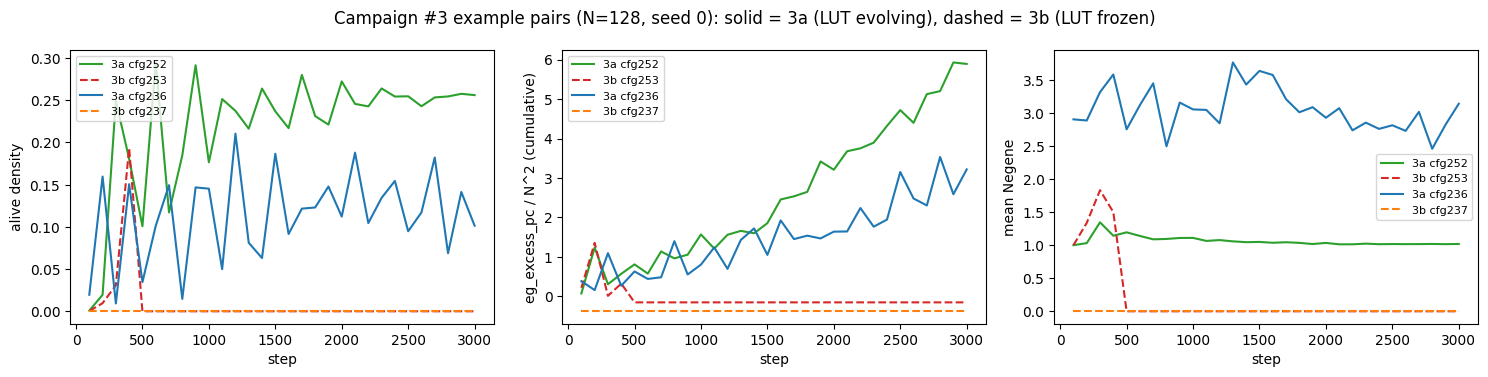

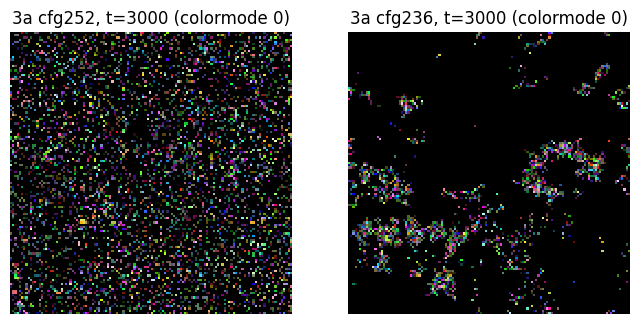

In [6]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
col = {'3a cfg252': 'C2', '3b cfg253': 'C3', '3a cfg236': 'C0', '3b cfg237': 'C1'}
for label, e in ex3.items():
    ts = e['ts']; ls = '-' if label.startswith('3a') else '--'
    ax[0].plot(ts.t, ts['pop'] / N3**2, ls, c=col[label], label=label)
    ax[1].plot(ts.t, ts['eg_excess'] / N3**2, ls, c=col[label], label=label)
    ax[2].plot(ts.t, ts['negene'], ls, c=col[label], label=label)
ax[0].set_ylabel('alive density'); ax[1].set_ylabel('eg_excess_pc / N^2 (cumulative)'); ax[2].set_ylabel('mean Negene')
for a in ax: a.set_xlabel('step'); a.legend(fontsize=8)
fig.suptitle('Campaign #3 example pairs (N=128, seed 0): solid = 3a (LUT evolving), dashed = 3b (LUT frozen)')
fig.tight_layout(); plt.show()
fig, ax = plt.subplots(1, 2, figsize=(8, 4))
for a, lab in zip(ax, ['3a cfg252', '3a cfg236']):
    a.imshow(ex3[lab]['frame'], interpolation='nearest'); a.set_title(lab + ', t=3000 (colormode 0)'); a.axis('off')
plt.show()

**Observations.**
- Recorded (campaign, N=256, 8000 steps): 3a eg-excess slope mean ~17.5 vs 3b ~1.7; extinction 12% (3a) vs 46% (3b).
  3b base regimes 5, 7, 9, 11 are 50-100% extinct (see `base_cfg` in `results.csv`).
- *Observed in this example run, N=128, seed 0, not a campaign result:* both 3a runs (252, 236) survive and accumulate egene excess; both 3b twins
  (253, 237) go extinct. 237 matches the record (extinct), but **253 survived in the recorded N=256 run** (alive density 0.142). In a scratch check
  (same `build_sim` call, seed 0, 3000 steps, N=128) config 253 survives with 2581 cells when the neutral shadow is **not** enabled and is extinct
  when it is (the shadow draws random kills, `C/evoca.c` near line 2418, consistent with it perturbing the RNG stream; not verified in C); seeds 1 and 2 are extinct either way, and enabling lineage tracking alone does not change the trajectory. So the viability of frozen
  GoL (3b) is a coin flip that even an RNG-stream perturbation from the shadow flips, which is the confound #3c was built to remove. (The example
  runs here have the shadow on, as the campaign did; the N and seed differ.)
- Absolute eg-excess depends on N and run length (the table divides by N^2 for a rough comparison), so only the ordering (3a >> 3b) is comparable with
  the record, not the magnitudes. The 3a example excess is lower than the recorded N=256, 8000-step value, as expected for fewer steps.
- Mean Negene at t=3000 is ~1 (252) and ~3 (236) in the 3a examples; no staircase is resolvable at 100-step sampling (see section 4c for a finer look).

**Directions that came out of it.** The 3b arm froze GoL, not an evolved substrate, so the gap conflates "freezing hurts" with
"GoL is a poor substrate". -> campaign #3c.

## 2. Campaign #3c (2026-05-19): evolve LUT-only, then freeze or keep co-evolving, while egene evolves

**Question.** Separate *substrate quality* from *freezing per se*. Single continuous sim: phase 1 evolves the LUT only
(3000 ticks); at the switch the rule is frozen (**A**) or left co-evolving (**C**) from a byte-identical shared substrate;
egene mutation is on in phase 2 (8000 ticks). **B** = frozen GoL, **B'** = GoL pre-run 100 ticks then frozen (anchors).
Regime (both phases): `m_scale=3.0, food_inc=0.015, tax=0.035, gdiff=0.06`.
Scan: [`Scans/2026-05-19_3c_coevolution_substrate/`](Scans/2026-05-19_3c_coevolution_substrate/notes.md); spec
[`Docs/plan-3c-coevolution-substrate.md`](../../Docs/plan-3c-coevolution-substrate.md); digest
[`digests/coevolution-substrate.ipynb`](digests/coevolution-substrate.ipynb) (draft).

**Recorded finding** (`notes.md`): the #3 gap is **mostly a GoL-substrate viability collapse**, not a clean synergy: B is 10/10
extinct; B' is viable but shows flat-zero egene excess. With the substrate byte-identical, co-evolving (C) beats freezing (A)
only modestly but consistently (paired C-A `eg_excess_pc` slope > 0 in 22/30, mean +0.6); absolute egene signal is weak
(|slopes| <~ 1 vs #1's 20-135) and plateaued by ticks 7-8k. **Caveat:** arm A's `dyn_excess_pc_slope ~ +335` is an artifact of
`mu_lut=0` on a rich evolved substrate (the dyn neutral baseline collapses), so `dyn_excess_pc` is uninterpretable there.

In [7]:
c3 = pd.read_csv(SCANS / '2026-05-19_3c_coevolution_substrate' / 'results.csv')
rec3c = c3.groupby('arm').agg(n=('arm', 'size'), extinct=('extinct', 'sum'),
                              eg_excess_pc_slope=('eg_excess_pc_slope', 'mean'),
                              dyn_excess_pc_slope=('dyn_excess_pc_slope', 'mean'),
                              determinism_ok=('determinism_ok', lambda s: s.dropna().astype(bool).all())
                              ).round(2).reindex(['A', 'C', 'B', "B'"])
print('Recorded #3c results.csv by arm (N=256, 3000+8000 ticks, 10 seeds x 3 phase-1 mu_lut):')
display(rec3c)

Recorded #3c results.csv by arm (N=256, 3000+8000 ticks, 10 seeds x 3 phase-1 mu_lut):


,n,extinct,eg_excess_pc_slope,dyn_excess_pc_slope,determinism_ok
arm,,,,,
A,30,0,-0.38,335.33,True
C,30,0,0.24,1.01,True
B,10,10,0.00,0.00,True
B',10,0,-0.00,0.00,True


**Example runs.** A scaled-down replica (N=96, phase 1 = 2000, phase 2 = 2000, phase-1 `mu_lut=0.03`, seeds 0-3), same
fork-by-determinism design as the scan (A and C re-run phase 1 with the same seed, and the LUT hashes at the switch are asserted
equal). Plus one B and one B' run (seed 0). Lineage tracking is on; the shadow is **not** re-baselined at the switch (that is
follow-up F1), so slopes are fit over phase 2 only, as in the scan.

In [8]:
REG3C = dict(m_scale=3.0, food_inc=0.015, tax=0.035, gdiff=0.06)

def new_3c(N, seed, mu_lut, lineage=True):
    s = EvoCA()
    s.init(N, mu_lut=mu_lut, mu_egene=0.0, mu_egenome=0.0, tax_per_egene=0.0, lineage=lineage, **REG3C)
    s.set_seed(seed)
    s.state(lut='gol', egenome='uniform', egenome_value=0b000011)
    s.set_v(np.random.default_rng(seed).integers(0, 2, (N, N), dtype=np.uint8))
    s.set_f_all(0.5); s.set_F_all(1.0); s.set_alive_halfplane(0)
    s.neutral_enable()
    return s

def run_3c(arm, seed, N=96, p1=2000, p2=2000, p1mu=0.03, keep_frame=False):
    mu1 = {'A': p1mu, 'C': p1mu, 'B': 0.0, "B'": 0.0}[arm]
    pre = 100 if arm == "B'" else p1
    s = new_3c(N, seed, mu1)
    for _ in range(pre):
        s.step()
    lh = s.get_lut_hashes().copy()
    if arm in ('A', 'B', "B'"):
        s.update_mu_lut(0.0)
    s.update_mu_egene(0.01); s.update_mu_egenome(0.01)
    rows = []
    for i in range(p2):
        s.step()
        if (i + 1) % 100 == 0:
            r = sample_basic(s); r['t'] = i + 1; rows.append(r)
    ts = pd.DataFrame(rows)
    out = dict(arm=arm, seed=seed, lh=lh, ts=ts, n_lineages=s.get_lineage_return().size,
               intake_tax=s.lineage_return_totals(),
               frame=render(s, 0) if keep_frame else None)
    s.free()
    return out

t0 = time.time()
runs3c = {}
for seed in range(4):
    for arm in ('A', 'C'):
        runs3c[(arm, seed)] = run_3c(arm, seed, keep_frame=(seed == 1))
runs3c[('B', 0)] = run_3c('B', 0)
runs3c[("B'", 0)] = run_3c("B'", 0)
print(f'{time.time()-t0:.1f}s')

rows = []
for (arm, seed), r in runs3c.items():
    ts = r['ts']
    rows.append(dict(arm=arm, seed=seed, min_pop=int(ts['pop'].min()), final_pop=int(ts['pop'].iloc[-1]),
                     eg_excess_slope=round(slope(ts.t, ts.eg_excess), 1),
                     dyn_excess_slope=round(slope(ts.t, ts.dyn_excess), 1),
                     dyn_excess_final=round(ts.dyn_excess.iloc[-1])))
tab = pd.DataFrame(rows)
display(tab.set_index(['arm', 'seed']))
for seed in range(4):
    assert np.array_equal(runs3c[('A', seed)]['lh'], runs3c[('C', seed)]['lh']), 'shared-substrate fork broken'
print('determinism: A and C LUT hashes identical at the switch for all 4 seeds')
pa = tab[tab.arm == 'A'].set_index('seed').eg_excess_slope
pc = tab[tab.arm == 'C'].set_index('seed').eg_excess_slope
print('paired C - A eg_excess slope:', (pc - pa).round(1).to_dict())

20.4s


,,min_pop,final_pop,eg_excess_slope,dyn_excess_slope,dyn_excess_final
arm,seed,,,,,
A,0,442,5796,-6.4,4.9,3738
C,0,197,3450,-10.3,4.6,6290
A,1,692,8017,-0.5,117.0,216296
C,1,242,4280,-1.5,-0.3,4786
A,2,1330,4833,1.6,-0.9,5523
C,2,131,5235,1.3,3.7,2883
A,3,322,5001,-14.2,-2.4,4082
C,3,248,516,11.8,1.2,31056
B,0,0,0,0.0,0.0,-1043702


determinism: A and C LUT hashes identical at the switch for all 4 seeds
paired C - A eg_excess slope: {0: -3.9, 1: -1.0, 2: -0.3, 3: 26.0}


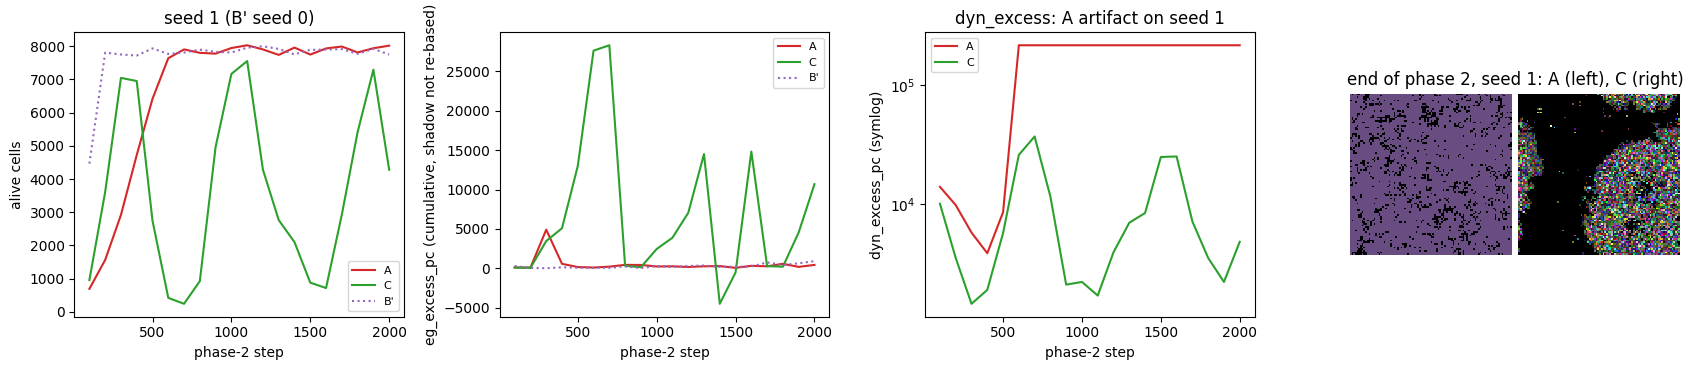

In [9]:
fig, ax = plt.subplots(1, 4, figsize=(17, 3.8))
for arm, c in (('A', 'C3'), ('C', 'C2')):
    ts = runs3c[(arm, 1)]['ts']
    ax[0].plot(ts.t, ts['pop'], c=c, label=arm); ax[1].plot(ts.t, ts.eg_excess, c=c, label=arm)
    ax[2].plot(ts.t, ts.dyn_excess, c=c, label=arm)
for arm, c in (("B'", 'C4'),):
    ts = runs3c[(arm, 0)]['ts']
    ax[0].plot(ts.t, ts['pop'], c=c, ls=':', label=arm); ax[1].plot(ts.t, ts.eg_excess, c=c, ls=':', label=arm)
ax[2].set_yscale('symlog')
ax[0].set_ylabel('alive cells'); ax[1].set_ylabel('eg_excess_pc (cumulative, shadow not re-based)')
ax[2].set_ylabel('dyn_excess_pc (symlog)')
for a in ax[:3]: a.set_xlabel('phase-2 step'); a.legend(fontsize=8)
ax[0].set_title('seed 1 (B\' seed 0)'); ax[2].set_title('dyn_excess: A artifact on seed 1')
ax[3].imshow(np.hstack([runs3c[('A', 1)]['frame'], np.full((96, 4, 3), 255, np.uint8), runs3c[('C', 1)]['frame']]),
             interpolation='nearest')
ax[3].set_title('end of phase 2, seed 1: A (left), C (right)'); ax[3].axis('off')
fig.tight_layout(); plt.show()

**Observations.**
- Recorded: see the by-arm table above (B 10/10 extinct; A and C viable; `determinism_ok` true on all 30 A/C pairs).
- *Observed in this example run (N=96, 4 seeds, not a campaign result):* the shared-substrate fork is bit-identical at the switch for all four seeds
  (the determinism property the scan asserted). B (plain frozen GoL) is extinct; B' stays viable with ~zero egene excess (slope +0.3), both consistent with
  the record.
- *Observed:* paired C-A egene-excess slopes are -3.9, -1.0, -0.3 and +26.0 for seeds 0-3: negative in three seeds, large positive in one (mean +5, dominated by seed 3).
  The recorded result (C > A in 22/30, mean +0.6) cannot be tested with four seeds at N=96; this is only a reminder that the paired difference is small
  relative to run-to-run scatter.
- *Observed:* the dyn-excess artifact appears in **one of four** A runs here (seed 1: `dyn_excess_pc` jumps to ~2e5 at about step 600 of phase 2 and stays flat; slope ~ +117, versus
  single digits for the other A seeds and for C). In the **recorded N=256 campaign it is systematic, not an outlier**: 21 of 30 A runs have `dyn_excess_pc_slope` > 50 (median +249, max +1096; larger at lower
  phase-1 `mu_lut`), against ~1 for C. So at N=96 / 2000 steps the artifact is intermittent and at N=256 / 8000 steps it is the norm. Either way, do **not** read `dyn_excess_pc` on a `mu_lut=0`
  evolved substrate as selection.
- *Observed:* in seed 1 the co-evolving arm C shows large boom-bust population cycles (about 250 to 7000 cells, period ~800 steps) while A and B' sit near a steady ~8000;
  C's cumulative `eg_excess_pc` rises and falls with those cycles. Cumulative excess without shadow re-baselining (follow-up F1) is therefore not a clean selection readout in absolute terms.

**Directions that came out of it.** The decisive clean test is the **direct** one: read the lineage field and ask whether LUT changes and
egene changes are *jointly retained* beyond independent mutation, with no shadow model. -> campaign #8.

## 3. Campaign #8 (2026-05-19, ON HOLD): direct lineage co-evolution metric and the binary-indicator degeneracy

**Question.** At the mutation step, LUT flips and egene changes are drawn by independent passes (`C/evoca.c` mutation code), so across
reproduction edges they are independent by construction. Any (dLUT, dEgene) association among **surviving** edges is selection
retaining co-adapted pairs: a direct, shadow-free co-evolution test. Spec and the 6 fix options (A-F):
[`Docs/plan-8-lineage-coevolution.md`](../../Docs/plan-8-lineage-coevolution.md). Harness (machinery built, never produced a
`results.csv`): [`Scans/2026-05-19_8_lineage_coevolution/scan.py`](Scans/2026-05-19_8_lineage_coevolution/scan.py).

**Recorded flaw (smoke test, N=64):** with `LUT_BITS=250`, `P(>=1 flip) = 1-exp(-250 mu_lut)` = 0.918 at 0.01, 0.9995 at 0.03.
The binary indicator "LUT hash changed?" saturates at every productive `mu_lut`, so phi ~ 0 trivially. Campaign put **on hold**.

**Example run.** Rebuild the edge table the way the harness does (lineage on from `init`, snapshot `(birth_id, parent_id, LUT bytes, egene
bytes)` every S=4 steps after a warm-up, reconstruct parent->child edges, keep surviving edges), but record **LUT bytes and egene bytes**,
not just hashes, so both the binary indicator and the Option A magnitude (Hamming distance) can be computed from the same edges.
N=64, warm-up 300, window 600, `mu_egene=mu_egenome=0.01`, 4 values of `mu_lut`.

In [10]:
from scipy.stats import spearmanr
_SLOT = np.arange(8, dtype=np.uint8)
_POP = np.array([bin(i).count('1') for i in range(256)], dtype=np.int32)

def egene_bytes(sim):
    """Per-cell egene identity bytes: active mask || 8 slot values || 8 slot masks (inactive slots zeroed)."""
    act = sim.get_active().ravel().astype(np.uint8)
    val = sim.get_egenes().reshape(-1, 8).astype(np.uint8)
    msk = sim.get_egenes_mask().reshape(-1, 8).astype(np.uint8)
    on = ((act[:, None] >> _SLOT) & 1).astype(bool)
    return np.concatenate([act[:, None], np.where(on, val, 0), np.where(on, msk, 0)], axis=1)

def ham(a, b):
    return int(_POP[np.bitwise_xor(a, b)].sum())

def edge_table(mu_lut, N=64, seed=3, t_warm=300, t_meas=600, S=4, t_surv=40):
    s = EvoCA()
    s.init(N, mu_lut=mu_lut, mu_egene=0.01, mu_egenome=0.01, lineage=True, **REG3C)  # lineage via init()
    s.set_seed(seed); s.state(lut='gol', egenome='uniform', egenome_value=3)
    s.set_v(np.random.default_rng(seed).integers(0, 2, (N, N), dtype=np.uint8))
    s.set_f_all(0.5); s.set_F_all(1.0); s.set_alive_halfplane(0)
    for _ in range(t_warm):
        s.step()
    rec = {}                                   # birth_id -> [lut bytes, egene bytes, parent_id, first_t, last_t]
    for k in range(t_meas // S + 1):
        if k:
            for _ in range(S):
                s.step()
        t = t_warm + k * S
        alive = s.get_alive().ravel() == 1
        if not alive.any():
            break
        bid = s.get_lineage_birth_id().ravel(); pid = s.get_lineage_parent_id().ravel()
        lut = np.ctypeslib.as_array(s._lib.evoca_get_lut(), shape=(N * N * LUT_BYTES,)).reshape(-1, LUT_BYTES)
        eg = egene_bytes(s)
        for i in np.flatnonzero(alive & (bid > 0)):
            b = int(bid[i]); r = rec.get(b)
            if r is None:
                rec[b] = [lut[i].copy(), eg[i].copy(), int(pid[i]), t, t]
            else:
                r[4] = t
    s.free()
    dl, de, sv = [], [], []
    for b, (l, e, p, f, la) in rec.items():
        pr = rec.get(p)
        if pr is None:
            continue
        dl.append(ham(l, pr[0])); de.append(ham(e, pr[1])); sv.append(la - f >= t_surv)
    return np.array(dl), np.array(de), np.array(sv)

def perm_p(x, y, n=300, seed=0):
    rng = np.random.default_rng(seed); obs = spearmanr(x, y)[0]; y = y.copy()
    null = np.array([spearmanr(x, rng.permutation(y))[0] for _ in range(n)])
    return obs, (np.sum(np.abs(null) >= abs(obs)) + 1) / (n + 1)

t0 = time.time()
edges8, rows = {}, []
for mu in (0.001, 0.003, 0.01, 0.03):
    dl, de, sv = edge_table(mu)
    edges8[mu] = (dl, de, sv)
    sd, se = dl[sv], de[sv]
    rho, p = perm_p(sd, se)
    rows.append({'mu_lut': mu, 'edges': dl.size, 'surviving edges': int(sv.sum()),
                 'analytic P(dLUT>0)': round(1 - np.exp(-250 * mu), 4),
                 'measured P(dLUT>0), all edges': round((dl > 0).mean(), 4),
                 'measured, surviving': round((sd > 0).mean(), 4),
                 'mean Hamming dLUT': round(dl.mean(), 2), 'expected 250*mu': round(250 * mu, 2),
                 'sd Hamming dLUT': round(dl.std(), 2),
                 'Spearman(dLUT Hamming, dEgene Hamming), surviving': round(rho, 3), 'perm p': round(p, 3)})
print(f'{time.time()-t0:.1f}s')
display(pd.DataFrame(rows).set_index('mu_lut').T)

3.1s


mu_lut,0.001,0.003,0.010,0.030
edges,133370.0000,32250.0000,22364.0000,22560.0000
surviving edges,5390.0000,7898.0000,9953.0000,10988.0000
analytic P(dLUT>0),0.2212,0.5276,0.9179,0.9994
"measured P(dLUT>0), all edges",0.2210,0.5270,0.9179,0.9995
"measured, surviving",0.2217,0.5236,0.9184,0.9994
mean Hamming dLUT,0.2500,0.7400,2.4900,7.3000
expected 250*mu,0.2500,0.7500,2.5000,7.5000
sd Hamming dLUT,0.5000,0.8600,1.5700,2.6700
"Spearman(dLUT Hamming, dEgene Hamming), surviving",-0.0080,-0.0020,0.0050,-0.0100
perm p,0.5320,0.8310,0.6110,0.2720


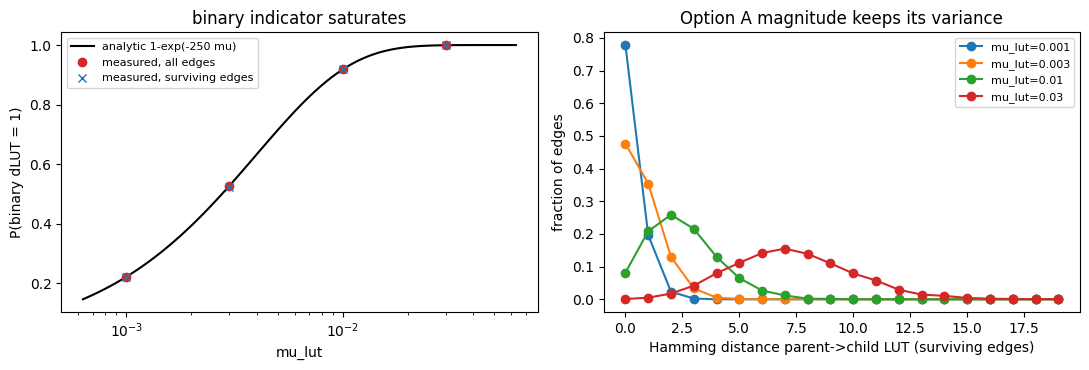

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
mus = np.array(list(edges8)); x = np.logspace(-3.2, -1.2, 100)
ax[0].plot(x, 1 - np.exp(-250 * x), 'k-', label='analytic 1-exp(-250 mu)')
ax[0].plot(mus, [(edges8[m][0] > 0).mean() for m in mus], 'o', c='C3', label='measured, all edges')
ax[0].plot(mus, [(edges8[m][0][edges8[m][2]] > 0).mean() for m in mus], 'x', c='C0', label='measured, surviving edges')
ax[0].set_xscale('log'); ax[0].set_xlabel('mu_lut'); ax[0].set_ylabel('P(binary dLUT = 1)')
ax[0].set_title('binary indicator saturates'); ax[0].legend(fontsize=8)
for m, c in zip(mus, ['C0', 'C1', 'C2', 'C3']):
    h = np.bincount(edges8[m][0][edges8[m][2]], minlength=20)[:20] / max(1, edges8[m][2].sum())
    ax[1].plot(np.arange(20), h, 'o-', c=c, label=f'mu_lut={m}')
ax[1].set_xlabel('Hamming distance parent->child LUT (surviving edges)'); ax[1].set_ylabel('fraction of edges')
ax[1].set_title('Option A magnitude keeps its variance'); ax[1].legend(fontsize=8)
fig.tight_layout(); plt.show()

**Observations.**
- *Observed in this example run (N=64, one seed per `mu_lut`, not a campaign result):* the binary dLUT indicator reproduces the recorded
  analytic saturation to three digits (0.918 at 0.01, 0.9995 at 0.03), on all edges **and** on surviving edges. The survival filter
  barely moves P(dLUT>0), which says survival over this window is nearly blind to *whether* the LUT changed at all.
- The Option A magnitude (Hamming distance of the 32 LUT bytes) has mean `250*mu_lut` and a spread that grows with `mu_lut`
  (sd 0.5 to 2.7), so it has variance where the binary indicator has none. Bulk LUT bytes are available with one pointer read
  (`evoca_get_lut`), so Option A is cheap at this N; no per-cell loop over `get_lut(idx)` is needed.
- The Spearman correlation between LUT-Hamming and egene-Hamming among surviving edges is ~0 with permutation p-values far from
  significant at every `mu_lut` here. That is **not** evidence of "no co-evolution": most flipped LUT bits are silent (never queried), so the
  magnitude is dominated by neutral noise, and one short window at N=64 has little power. This is exactly why the plan pairs A with
  Option F (flips restricted to queried bits, `restricted_mu`) and why an *outcome* variable (see section 4) matters.

**Directions that came out of it.** The redesign decision (which fix option) is deferred to N and recorded as **LIN-D1** in
[`ISSUES.md`](ISSUES.md); the 2026-10-15 merge of the D2 reducer changes the menu (section 4 and section 5).

## 4. 2026-10-15: lineage field + D2 per-lineage net-return reducer on `main` (new example runs)

**What is newly available.** `sim.init(N, ..., lineage=True)` records the lineage field; `get_lineage_return()` returns one row per
distinct **full-genome hash** (LUT || egene) with cumulative `intake`, `tax`, `net`, `births`, live `pop`, `first_step`, `last_step`;
`lineage_return_totals()` is the run-cumulative cross-check. (`enable_lineage()` before `init` raises; after `init`, current cells
become founders.) The reducer counts **nominal** tax; the dissipation accountant counts tax actually removed, so they differ on
tax-death steps. Tests: [`tests/notebooks/lineage-return-test.ipynb`](../../tests/notebooks/lineage-return-test.ipynb).

The H1/D3 programs want **per-lineage net-return trajectories**, **longevity vs net return**, and a comparison between an **evolving run
and a frozen-mutation control**. Examples below use the #3c regime at N=96.

### 4a. What does a hash-keyed "lineage" resolve at different `mu_lut`?

The reducer keys on the full-genome hash, so a "lineage" is a *genotype*, not a clade. Before reading trajectories, check how many cells
share each genotype. (`mu_egene = mu_egenome = 0.01`, 2000 steps, seed 2, N=96.)

In [12]:
def run_lineage(N, seed, mu_lut, mu_eg, mu_egn, egenome, T, every=25, min_births=10, mu_off_after=None):
    s = EvoCA()
    s.init(N, mu_lut=mu_lut, mu_egene=mu_eg, mu_egenome=mu_egn, tax_per_egene=0.0, lineage=True, **REG3C)
    s.set_seed(seed); s.state(lut='gol', egenome=egenome, egenome_value=3)
    s.set_v(np.random.default_rng(seed).integers(0, 2, (N, N), dtype=np.uint8))
    s.set_f_all(0.5); s.set_F_all(1.0); s.set_alive_halfplane(0)
    snaps, agg = [], []
    for i in range(T):
        s.step()
        if (i + 1) % every == 0:
            r = s.get_lineage_return()                    # refreshes pop / last_step
            snaps.append((i + 1, r[r['births'] >= min_births].copy()))
            agg.append(dict(t=i + 1, pop=int(s.get_alive().sum()), negene=mean_negene(s),
                            net_total=float(r['net'].sum()), n_lin=r.size))
    red = s.get_lineage_return()
    it, tx = s.lineage_return_totals()
    frame = render(s, 3)
    diss = s.get_dissipation()
    s.free()
    return dict(red=red, snaps=snaps, agg=pd.DataFrame(agg), totals=(it, tx), frame=frame, diss=diss)

t0 = time.time()
rows = []
for mu in (0.001, 0.003, 0.01, 0.03):
    r = run_lineage(96, 2, mu, 0.01, 0.01, 'uniform', 2000, every=2000)
    red = r['red']; live = red[red['pop'] > 0]
    shared = live['pop'][live['pop'] >= 2].sum() / max(1, live['pop'].sum())
    rows.append({'mu_lut': mu, 'hash-lineages ever': red.size, 'alive cells': int(live['pop'].sum()),
                 'distinct live genotypes': live.size,
                 'frac of alive cells sharing genotype': round(float(shared), 3),
                 'max births in one lineage': int(red['births'].max()),
                 'lineages with >=10 births': int((red['births'] >= 10).sum()),
                 'reducer sum(intake)-total': float(red['intake'].sum() - r['totals'][0]),
                 'reducer sum(tax)-total': float(red['tax'].sum() - r['totals'][1])})
print(f'{time.time()-t0:.1f}s')
display(pd.DataFrame(rows).set_index('mu_lut').T)

6.4s


mu_lut,0.001,0.003,0.010,0.030
hash-lineages ever,5.823170e+05,2.847010e+05,1.998350e+05,1.984440e+05
alive cells,6.385000e+03,3.160000e+03,4.100000e+02,3.200000e+02
distinct live genotypes,4.788000e+03,2.628000e+03,4.080000e+02,3.200000e+02
frac of alive cells sharing genotype,4.280000e-01,2.970000e-01,1.000000e-02,0.000000e+00
max births in one lineage,4.305000e+03,2.223000e+03,3.760000e+02,2.000000e+00
lineages with >=10 births,3.612000e+03,1.580000e+02,9.000000e+00,0.000000e+00
reducer sum(intake)-total,5.238689e-10,-8.731149e-10,6.402843e-10,-7.566996e-10
reducer sum(tax)-total,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00


*Observed in this example run (N=96, seed 2, not a campaign result):* at `mu_lut <= 0.003` a few genotypes grow large lineages (hundreds to
thousands of births), but at `mu_lut >= 0.01` nearly every live cell carries a unique genotype, and no lineage reaches 10 births at 0.03.
At productive `mu_lut` the per-hash net return is therefore a **per-individual** lifetime net return, not a clade property.
This is the lineage-field analog of the #8 saturation: mutation outruns the genotype key. For H1 at `mu_lut >= 0.01` the lineage
unit should be a clade (roll up along `parent_id` chains) or a phenotype-level key. The completeness cross-check (reducer sums equal
`lineage_return_totals`) holds to float precision in every row.

### 4b. Per-lineage net-return trajectories and longevity vs net return: evolving run vs frozen-mutation control

- **Evolving run:** `mu_lut=0.0003, mu_egene=mu_egenome=0.003` from uniform egenome on GoL (mutation slow enough that large lineages exist to follow; at `mu_lut >= 0.003` the top lineages are gone within a few hundred steps, see 4a).
- **Frozen-mutation control:** all mutation rates 0, egenomes randomized at start (`egenome='random'`), so a standing library of fixed genotypes competes
  by selection alone (no new variation). Same regime, size, and seed.

N=96, 3000 steps, `get_lineage_return()` sampled every 25 steps (rows with >= 10 births kept). Top 8 lineages by final births are drawn.
Per-capita rate = d(net)/(dt * mean pop) between samples.

9.2s


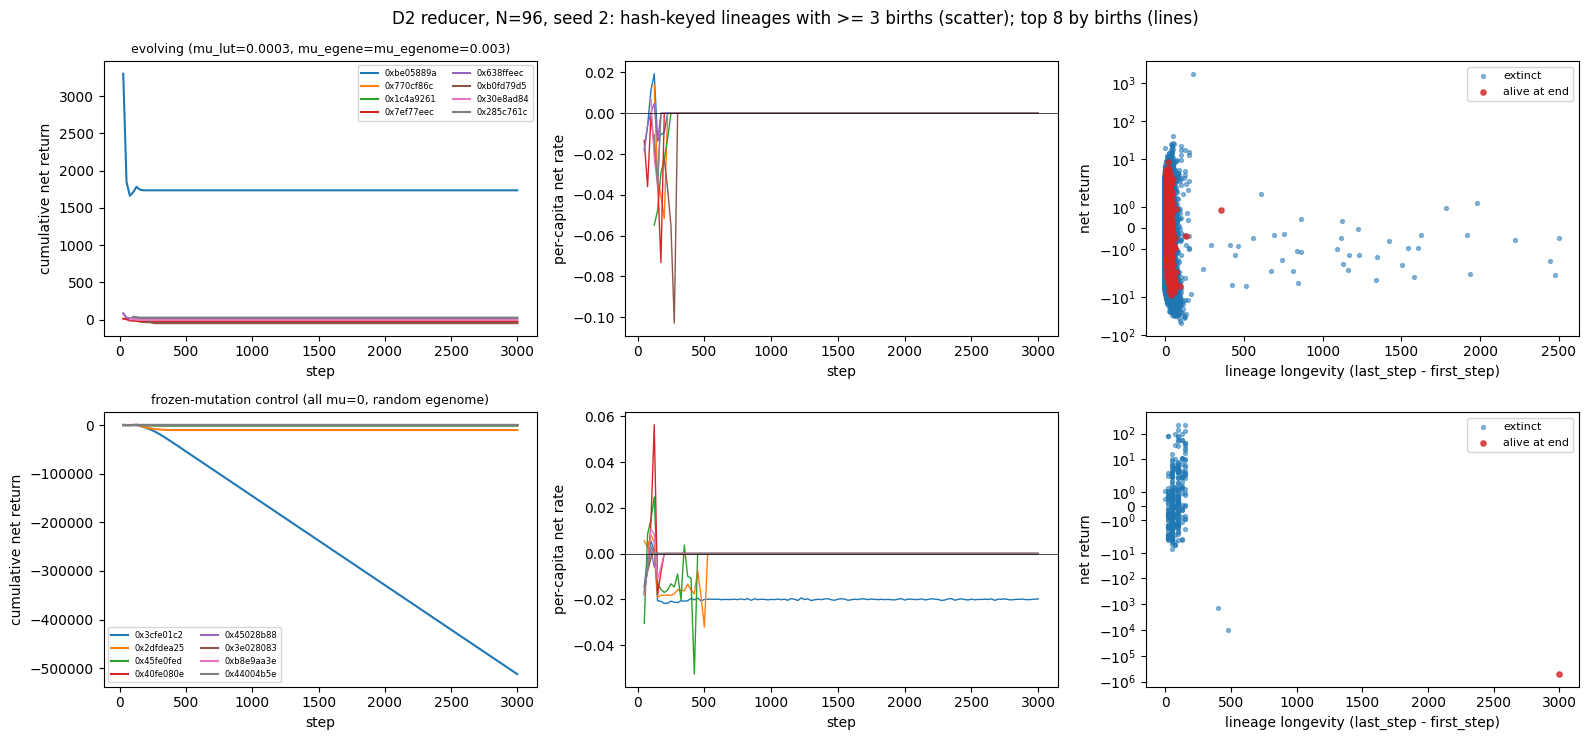

,hash-lineages ever,with >=3 births,final pop,"Spearman(longevity, net), >=3 births",frac with net<0,total intake,"tax, reducer (nominal)","tax, dissipation accountant (actual)",source (food_inc * N^2 * T)
run,,,,,,,,,
evolving,1143197,569530,7954,-0.131,0.702,414067,887729,738159,414720
control,681,334,9136,0.326,0.488,416977,939192,763713,414720


In [13]:
t0 = time.time()
evo = run_lineage(96, 2, 0.0003, 0.003, 0.003, 'uniform', 3000)
ctl = run_lineage(96, 2, 0.0, 0.0, 0.0, 'random', 3000)
print(f'{time.time()-t0:.1f}s')

def trajectories(r, top=8):
    red = r['red']
    ids = red['hash'][np.argsort(red['births'].astype(np.int64))[::-1][:top]]
    out = {}
    for h in ids:
        tt, net, pop = [], [], []
        for t, sn in r['snaps']:
            m = sn['hash'] == h
            if m.any():
                tt.append(t); net.append(float(sn['net'][m][0])); pop.append(int(sn['pop'][m][0]))
        out[int(h)] = (np.array(tt), np.array(net), np.array(pop))
    return out

fig, ax = plt.subplots(2, 3, figsize=(16, 7.5))
for row, (name, r) in enumerate((('evolving (mu_lut=0.0003, mu_egene=mu_egenome=0.003)', evo), ('frozen-mutation control (all mu=0, random egenome)', ctl))):
    tr = trajectories(r)
    for k, (h, (tt, net, pop)) in enumerate(tr.items()):
        ax[row, 0].plot(tt, net, c=f'C{k}', label=f'0x{h:08x}')
        if len(tt) > 2:
            rate = np.diff(net) / (np.diff(tt) * np.maximum(1, 0.5 * (pop[1:] + pop[:-1])))
            ax[row, 1].plot(tt[1:], rate, c=f'C{k}', lw=1)
    ax[row, 0].set_ylabel('cumulative net return'); ax[row, 0].set_title(name, fontsize=9)
    ax[row, 1].set_ylabel('per-capita net rate'); ax[row, 1].axhline(0, c='k', lw=0.5)
    red = r['red']; k = red['births'] >= 3
    dur = (red['last_step'].astype(float) - red['first_step'])[k]
    alive = (red['pop'] > 0)[k]
    ax[row, 2].scatter(dur[~alive], red['net'][k][~alive], s=8, c='C0', alpha=0.5, label='extinct')
    ax[row, 2].scatter(dur[alive], red['net'][k][alive], s=14, c='C3', alpha=0.8, label='alive at end')
    ax[row, 2].set_xlabel('lineage longevity (last_step - first_step)'); ax[row, 2].set_ylabel('net return')
    ax[row, 2].set_yscale('symlog'); ax[row, 2].legend(fontsize=8)
    ax[row, 0].legend(fontsize=6, ncol=2); ax[row, 0].set_xlabel('step'); ax[row, 1].set_xlabel('step')
fig.suptitle('D2 reducer, N=96, seed 2: hash-keyed lineages with >= 3 births (scatter); top 8 by births (lines)')
fig.tight_layout(); plt.show()

rows = []
for name, r in (('evolving', evo), ('control', ctl)):
    red = r['red']; k = red['births'] >= 3
    dur = (red['last_step'].astype(float) - red['first_step'])[k]
    net = red['net'][k]
    from scipy.stats import spearmanr as _sp
    rows.append({'run': name, 'hash-lineages ever': red.size, 'with >=3 births': int(k.sum()),
                 'final pop': int(r['agg']['pop'].iloc[-1]),
                 'Spearman(longevity, net), >=3 births': round(float(_sp(dur, net)[0]), 3) if k.sum() > 3 else None,
                 'frac with net<0': round(float((net < 0).mean()), 3) if k.sum() else None,
                 'total intake': round(r['totals'][0]), 'tax, reducer (nominal)': round(r['totals'][1]),
                 'tax, dissipation accountant (actual)': round(r['diss']['tax_cum']),
                 'source (food_inc * N^2 * T)': round(0.015 * 96**2 * 3000)})
display(pd.DataFrame(rows).set_index('run'))

**Observations** (*observed in this example run, N=96, seed 2, one run per arm; not a campaign result*):
- **Resource-limited steady state pins raw net return.** Total intake is ~414,000 in both runs, equal to the food source (`food_inc * N^2 * T` = 414,720): intake is
  resource-bound, not genotype-bound. In the control, the one dominant genotype has a constant per-capita net rate of about -0.020 per step for 2500+ steps
  (cumulative net ~ -5e5). That is what the arithmetic predicts for a saturated lattice: `food_inc * N^2 / pop - tax = 0.015*9216/9136 - 0.035 = -0.0199`.
  So raw cumulative or per-capita net return carries no fitness information between coexisting genotypes here; it measures the pool share. Adaptive-vs-drift
  claims must compare net return **against a neutral expectation** (shadow or matched-null), as the checkpoint section H step 2 says, not read it directly.
- **Nominal vs actual tax is material.** Reducer tax (nominal) exceeds the dissipation accountant's tax actually removed by about 20-23% in these runs (table). The reducer's net is
  therefore biased low by the tax that a dying cell could not pay; for per-lineage comparisons this bias is larger for short-lived lineages.
- **Genotype lineages are short-lived in the evolving run.** The top-8 lineages by births are all early (founder-wave) genotypes that are gone by about step 300; after that, no hash reaches
  10 births at any sample, so the steady state is a swarm of short-lived genotypes (1.1 million hash-lineages in 3000 steps). The control has 681 lineages and one winner.
- **Longevity vs net return is weak and sign-unstable.** Spearman(longevity, net) is -0.13 in the evolving run and +0.33 in the control (lineages with >= 3 births). Longevity here is quantized by the
  25-step sampling interval, because `last_step` is only as current as the last `lineage_return_update()`/`get_lineage_return()` call. A neutral lineage that is early and large also shows long life and
  large |net|, so the scatter alone cannot separate adaptation from drift.

### 4c. D3 preview: aggregate per-capita net return alongside mean Negene (no detector built)

The punctuation hypothesis (checkpoint section D, N's 2026-07-19 reply on section D) is a dip-then-staircase in lineage net return
when a lineage gains an egene. D3 (detector) is **not** built. As a feasibility check only: in the evolving run, plot mean Negene and the
population-wide per-capita net rate (d(sum net)/dt / pop) on one time axis.

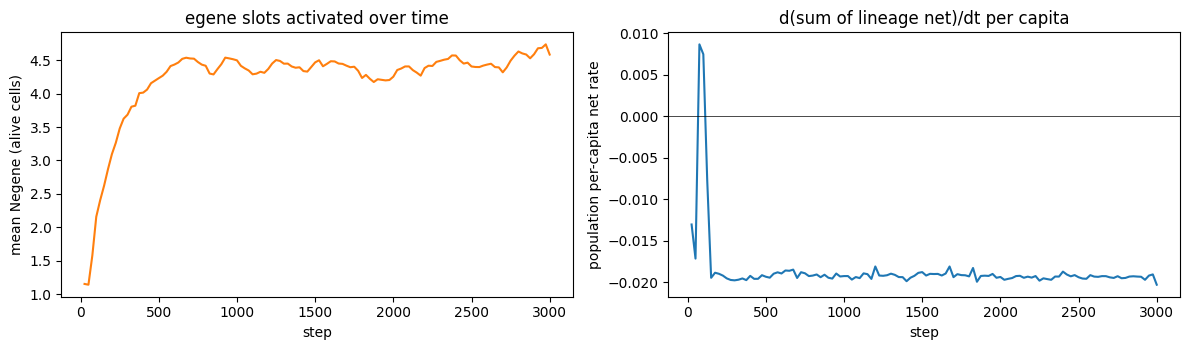

mean Negene: start 1.15, max 4.74, end 4.58


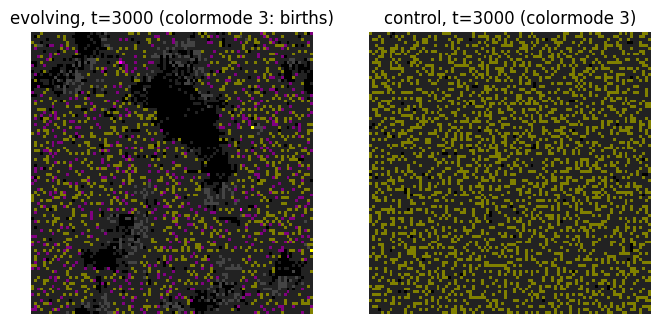

In [14]:
a = evo['agg']
rate = np.gradient(a.net_total.values, a.t.values) / np.maximum(1, a['pop'].values)
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
ax[0].plot(a.t, a.negene, c='C1'); ax[0].set_ylabel('mean Negene (alive cells)'); ax[0].set_xlabel('step')
ax[0].set_title('egene slots activated over time')
ax[1].plot(a.t, rate, c='C0'); ax[1].set_ylabel('population per-capita net rate'); ax[1].set_xlabel('step')
ax[1].axhline(0, c='k', lw=0.5); ax[1].set_title('d(sum of lineage net)/dt per capita')
fig.tight_layout(); plt.show()
print('mean Negene: start %.2f, max %.2f, end %.2f' % (a.negene.iloc[0], a.negene.max(), a.negene.iloc[-1]))
fig, ax = plt.subplots(1, 2, figsize=(8, 4))
ax[0].imshow(evo['frame'], interpolation='nearest'); ax[0].set_title('evolving, t=3000 (colormode 3: births)'); ax[0].axis('off')
ax[1].imshow(ctl['frame'], interpolation='nearest'); ax[1].set_title('control, t=3000 (colormode 3)'); ax[1].axis('off')
plt.show()

*Observed in this example run:* mean Negene rises from ~1.2 to ~4.7 within the first ~500 steps and then wanders between ~3.6 and ~5.3, so there is no clean single staircase to detect at the population level. The population-level net-rate series is noisy and dominated by population swings, so a staircase in per-lineage net
return would have to be extracted at the lineage level (a lineage that *gains* an egene slot, tracked across the change), not from
population averages. That requires knowing, per lineage, when Negene stepped: the reducer keys on the full-genome hash, so a Negene
change creates a **new** hash row; the detector must link parent hash to child hash (the `lineage_parent_hash` field supplies the
parent's hash for each newborn, so the link exists but is not yet exposed as a table). This is the main piece of D3 dev work.

## 5. Current state and directions (2026-10)

**Where things stand.**
- **Established, recorded:** #3: 3a >> 3b but confounded (3b froze GoL, 46% extinct). #3c: the gap is mostly GoL-substrate death (B 10/10 extinct,
  B' viable with ~0 egene excess); C beats A only modestly but consistently (22/30, mean +0.6), with a weak egene signal that plateaus by 7-8k ticks;
  `dyn_excess_pc` is an artifact on frozen-rich substrates. **The scientific question (adaptive co-evolution vs joint drift) is still open**:
  the indirect, shadow-based campaigns could not answer it and the direct one (#8) has no data.
- **Newly unblocked by the 2026-10-15 merges (lineage field + D2 reducer):** D3 (punctuation detector) and H1 (adaptive-vs-drift program) can start on
  `main`, and the #8 redesign can use a per-lineage fitness outcome. Section 4 shows the reducer works at N=96 and that it is **genotype-keyed**.
- **What the example runs add (single seed, small N, not campaign results):** (i) frozen-GoL viability (3b) is a coin flip on N, seed and even the RNG stream (enabling the shadow flipped one outcome);
  (ii) the shared-substrate fork is bit-identical at small N; (iii) the dyn-excess artifact is intermittent at N=96 (1 of 4 A runs) but systematic in the N=256 record (21/30 A runs > 50);
  (iv) the binary dLUT indicator reproduces the analytic saturation, and the Hamming magnitude does not saturate;
  (v) at `mu_lut >= 0.01`, hash-keyed lineages are near-singletons, so H1 at productive `mu_lut` needs clade roll-up;
  (vi) raw net return is pinned by the food-share-minus-tax arithmetic in a saturated lattice (intake equals the food source), so it must be compared to a neutral expectation, and the reducer's nominal tax runs ~20% above the tax actually removed.
- **Outstanding decisions, see [`ISSUES.md`](ISSUES.md):** LIN-D1 (#8 redesign option), LIN-D2 (lineage unit for H1 at productive `mu_lut`).

In [15]:
print(f'notebook wall time: {time.time()-T_NOTEBOOK:.0f}s')

notebook wall time: 45s
